# Retail Sales Performance Analysis

## Project Overview

This project analyzes retail transaction data from July to December 2019 to understand sales performance, brand contribution, product demand, and customer purchasing behavior.

The analysis focuses on identifying sales trends, comparing brand performance, examining product-level patterns, and understanding customer retention.

## Business Questions

1. How did sales performance change from July to December 2019?
2. Which brands contributed the most to sales quantity and GMV?
3. What patterns can be observed in product demand and pricing?
4. How were sales distributed across regions?
5. How often did customers purchase, and how many returned in the following quarter?

In [188]:
import os
import datetime
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(os.path.expanduser("~/Downloads/retail_raw_reduced.csv"))

df.head()

,order_id,order_date,customer_id,city,province,product_id,brand,quantity,item_price
0,1703458,2019-10-17,14004,Jakarta Selatan,DKI Jakarta,P1910,BRAND_J,10,740000
1,1706815,2019-10-24,17220,Jakarta Selatan,DKI Jakarta,P2934,BRAND_R,2,604000
2,1710718,2019-11-03,16518,Jakarta Utara,DKI Jakarta,P0908,BRAND_C,8,1045000
3,1683592,2019-08-19,16364,Jakarta Barat,DKI Jakarta,P0128,BRAND_A,4,205000
4,1702573,2019-10-16,15696,Jakarta Timur,DKI Jakarta,P2968,BRAND_R,2,4475000


In [189]:
df.shape

(5000, 9)

In [190]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   order_id     5000 non-null   int64
 1   order_date   5000 non-null   str  
 2   customer_id  5000 non-null   int64
 3   city         5000 non-null   str  
 4   province     5000 non-null   str  
 5   product_id   5000 non-null   str  
 6   brand        5000 non-null   str  
 7   quantity     5000 non-null   int64
 8   item_price   5000 non-null   int64
dtypes: int64(4), str(5)
memory usage: 351.7 KB


In [191]:
df.describe()

,order_id,customer_id,quantity,item_price
count,5.000000e+03,5000.000000,5000.000000,5.000000e+03
mean,1.707214e+06,15474.832600,11.407200,9.345866e+05
std,2.152582e+04,1650.211651,29.404536,1.031427e+06
min,1.666774e+06,12391.000000,1.000000,2.600000e+04
25%,1.688852e+06,14096.000000,2.000000,4.500000e+05
50%,1.708448e+06,15492.500000,5.000000,6.040000e+05
75%,1.725623e+06,16916.000000,12.000000,1.045000e+06
max,1.742998e+06,18287.000000,720.000000,2.976200e+07


## 1. Data Preparation

Before analyzing sales performance, the dataset needs to be checked for duplicate records and reviewed for its date coverage.

This step helps ensure that the analysis is based on a consistent dataset and that the period covered by the data is clearly understood.

In [192]:
df.duplicated().sum()

np.int64(7)

In [193]:
df[df.duplicated()]

,order_id,order_date,customer_id,city,province,product_id,brand,quantity,item_price
954,1737007,2019-12-22,14093,Jakarta Pusat,DKI Jakarta,P1730,BRAND_H,1,450000
2441,1737424,2019-12-23,17019,Jakarta Pusat,DKI Jakarta,P3012,BRAND_R,1,590000
2460,1710733,2019-11-03,14514,Jakarta Barat,DKI Jakarta,P1735,BRAND_H,12,590000
2517,1736995,2019-12-22,15436,Yogyakarta,Yogyakarta,P2865,BRAND_R,1,1045000
3329,1718197,2019-11-19,18079,Jakarta Timur,DKI Jakarta,P0674,BRAND_C,12,159000
3579,1736779,2019-12-22,18156,Malang,Jawa Timur,P2935,BRAND_R,1,1500000
3750,1720504,2019-11-25,18055,Jakarta Selatan,DKI Jakarta,P0061,BRAND_A,2,3144000


In [194]:
  df[df.duplicated(keep=False)]

,order_id,order_date,customer_id,city,province,product_id,brand,quantity,item_price
68,1737007,2019-12-22,14093,Jakarta Pusat,DKI Jakarta,P1730,BRAND_H,1,450000
786,1710733,2019-11-03,14514,Jakarta Barat,DKI Jakarta,P1735,BRAND_H,12,590000
954,1737007,2019-12-22,14093,Jakarta Pusat,DKI Jakarta,P1730,BRAND_H,1,450000
1382,1737424,2019-12-23,17019,Jakarta Pusat,DKI Jakarta,P3012,BRAND_R,1,590000
1824,1736995,2019-12-22,15436,Yogyakarta,Yogyakarta,P2865,BRAND_R,1,1045000
2441,1737424,2019-12-23,17019,Jakarta Pusat,DKI Jakarta,P3012,BRAND_R,1,590000
2460,1710733,2019-11-03,14514,Jakarta Barat,DKI Jakarta,P1735,BRAND_H,12,590000
2517,1736995,2019-12-22,15436,Yogyakarta,Yogyakarta,P2865,BRAND_R,1,1045000
2725,1718197,2019-11-19,18079,Jakarta Timur,DKI Jakarta,P0674,BRAND_C,12,159000
2749,1720504,2019-11-25,18055,Jakarta Selatan,DKI Jakarta,P0061,BRAND_A,2,3144000


In [195]:
# Remove all duplicate rows and update the DataFrame
df_clean = df.drop_duplicates()

In [196]:
print("Remaining duplicate rows:", df_clean.duplicated().sum())

Remaining duplicate rows: 0


### Data Cleaning Summary

The dataset initially contained 5,000 rows. After removing 7 duplicate records, 4,993 rows remained for further analysis.

Removing duplicate records helps reduce the risk of counting the same transaction record more than once.

In [197]:
df_clean.shape

(4993, 9)

In [198]:
df_clean["order_date"].min(), df_clean["order_date"].max()

('2019-07-01', '2019-12-31')

In [199]:
print("Total rows:", df_clean.shape[0])
print("Unique orders:", df_clean["order_id"].nunique())
print("Unique customers:", df_clean["customer_id"].nunique())
print("Unique products:", df_clean["product_id"].nunique())
print("Unique brands:", df_clean["brand"].nunique())
print("Total quantity sold:", df_clean["quantity"].sum())

Total rows: 4993
Unique orders: 3234
Unique customers: 1773
Unique products: 1322
Unique brands: 10
Total quantity sold: 57006


In [200]:
df_clean["brand"].value_counts()

brand
BRAND_S    989
BRAND_P    665
BRAND_R    624
BRAND_C    535
BRAND_A    426
BRAND_W    385
BRAND_L    374
BRAND_B    344
BRAND_J    334
BRAND_H    317
Name: count, dtype: int64

In [201]:
df_clean["brand"].value_counts(dropna=False)

brand
BRAND_S    989
BRAND_P    665
BRAND_R    624
BRAND_C    535
BRAND_A    426
BRAND_W    385
BRAND_L    374
BRAND_B    344
BRAND_J    334
BRAND_H    317
Name: count, dtype: int64

## 2. Sales Performance Overview

This section examines monthly sales performance from July to December 2019 using two metrics:

- **Total Quantity Sold:** the total number of units sold each month.
- **Gross Merchandise Value (GMV):** the total transaction value, calculated by multiplying item price by quantity.

Comparing these metrics helps identify changes in sales volume and transaction value over time.

In [202]:
df_clean["order_month"] = df_clean["order_date"].apply(
    lambda x: datetime.datetime.strptime(x, "%Y-%m-%d").strftime("%Y-%m")
)

df_clean["gmv"] = df_clean["item_price"] * df_clean["quantity"]

In [203]:
print("Date range:", df_clean["order_date"].min(), "to", df_clean["order_date"].max())
print("Total quantity sold:", df_clean["quantity"].sum())
print("Total GMV:", df_clean["gmv"].sum())
print("Number of months:", df_clean["order_month"].nunique())

Date range: 2019-07-01 to 2019-12-31
Total quantity sold: 57006
Total GMV: 32955506000
Number of months: 6


In [204]:
monthly_sales = (
    df_clean.groupby("order_month")
    .agg(
        total_quantity=("quantity", "sum"),
        total_gmv=("gmv", "sum")
    )
    .reset_index()
)

print(monthly_sales)

  order_month  total_quantity   total_gmv
0     2019-07            6437  3524041000
1     2019-08            8122  4452923000
2     2019-09            6959  3947002000
3     2019-10           11195  6719937000
4     2019-11           10786  6166953000
5     2019-12           13507  8144650000


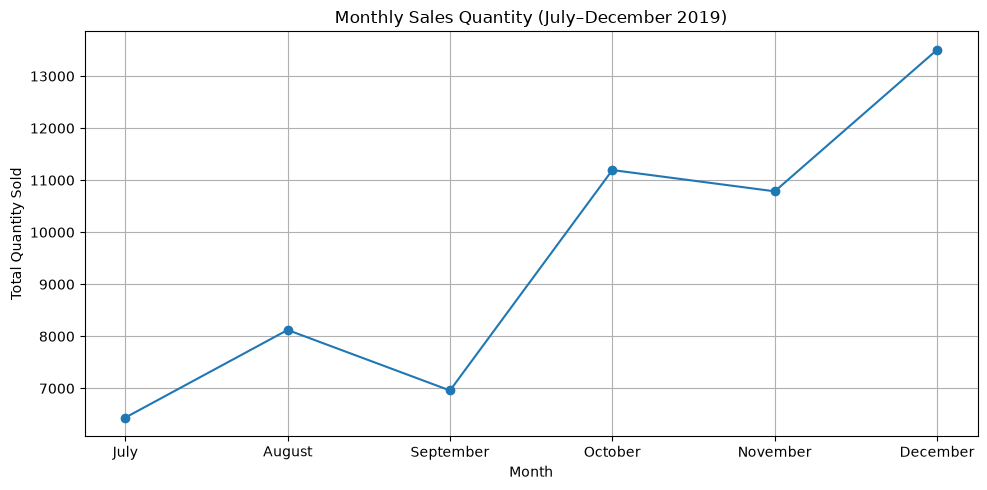

In [205]:
# Visualize monthly sales performance
plt.figure(figsize=(10, 5))

month_names = ["July", "August", "September", "October", "November", "December"]

plt.plot(
    month_names,
    monthly_sales["total_quantity"],
    marker="o"
)

plt.title("Monthly Sales Quantity (July–December 2019)")
plt.xlabel("Month")
plt.ylabel("Total Quantity Sold")
plt.grid(True)
plt.tight_layout()
plt.show()

**Key Takeaway**

Monthly sales quantity fluctuated throughout the observed period. Sales volume increased from July to August, declined in September, and rose substantially in October. Although volume decreased slightly in November, December recorded the highest sales quantity at 13,507 units.

Overall, sales volume showed an upward trend toward the end of 2019, despite some month-to-month fluctuations.

## Brand Performance by Sales Quantity

This section identifies the five brands with the highest total sales quantity from July to December 2019. Comparing sales volume across brands helps highlight which brands contributed most to the number of units sold.

In [206]:
# Calculate total quantity sold by brand
brand_sales = (
    df_clean.groupby("brand")["quantity"]
    .sum()
    .sort_values(ascending=False)
)

print(brand_sales)

brand
BRAND_P    10130
BRAND_S     9645
BRAND_A     5750
BRAND_W     5609
BRAND_C     5354
BRAND_R     5313
BRAND_J     4926
BRAND_B     3964
BRAND_H     3225
BRAND_L     3090
Name: quantity, dtype: int64


In [207]:
# Select the top 5 brands by total quantity sold
top5_brands = brand_sales.head(5)

print(top5_brands)

brand
BRAND_P    10130
BRAND_S     9645
BRAND_A     5750
BRAND_W     5609
BRAND_C     5354
Name: quantity, dtype: int64


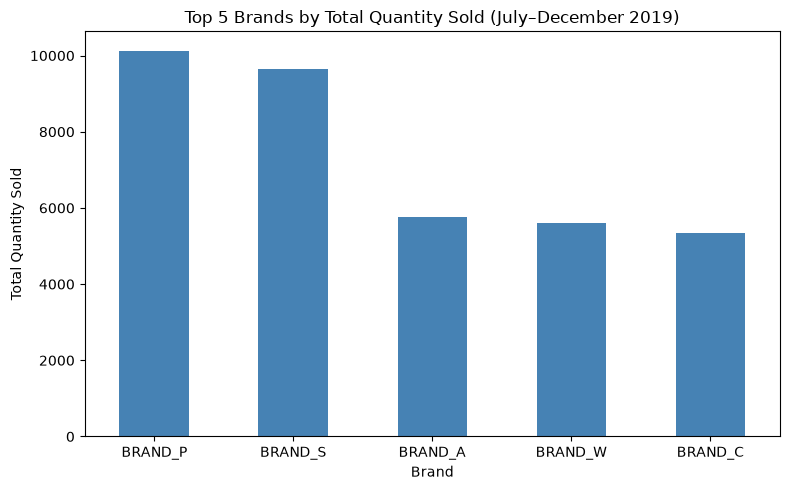

In [208]:
# Visualize the top 5 brands by total quantity sold
top5_brands.plot(kind="bar", figsize=(8, 5), color="steelblue")

plt.title("Top 5 Brands by Total Quantity Sold (July–December 2019)")
plt.xlabel("Brand")
plt.ylabel("Total Quantity Sold")
plt.ylim(ymin=0)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Key Takeaway**

BRAND_P recorded the highest total sales quantity at 10,130 units, followed by BRAND_S with 9,645 units. The gap between these two brands and the remaining top-five brands suggests that sales volume was concentrated among the leading brands.

However, sales quantity alone does not indicate which brands generated the highest transaction value. This will be examined through the GMV analysis.

In [209]:
# Calculate monthly quantity sold for the top 5 brands
top5_monthly_sales = (
    df_clean[df_clean["brand"].isin(top5_brands.index)]
    .groupby(["order_month", "brand"])["quantity"]
    .sum()
    .reset_index()
)

print(top5_monthly_sales)

   order_month    brand  quantity
0      2019-07  BRAND_A       837
1      2019-07  BRAND_C       420
2      2019-07  BRAND_P       960
3      2019-07  BRAND_S      1319
4      2019-07  BRAND_W       458
5      2019-08  BRAND_A       997
6      2019-08  BRAND_C       584
7      2019-08  BRAND_P      1495
8      2019-08  BRAND_S      1277
9      2019-08  BRAND_W       520
10     2019-09  BRAND_A       618
11     2019-09  BRAND_C       483
12     2019-09  BRAND_P      1309
13     2019-09  BRAND_S      1162
14     2019-09  BRAND_W       572
15     2019-10  BRAND_A      1096
16     2019-10  BRAND_C      1170
17     2019-10  BRAND_P      1901
18     2019-10  BRAND_S      2153
19     2019-10  BRAND_W      1223
20     2019-11  BRAND_A       887
21     2019-11  BRAND_C      1332
22     2019-11  BRAND_P      2271
23     2019-11  BRAND_S      1537
24     2019-11  BRAND_W      1584
25     2019-12  BRAND_A      1315
26     2019-12  BRAND_C      1365
27     2019-12  BRAND_P      2194
28     2019-12

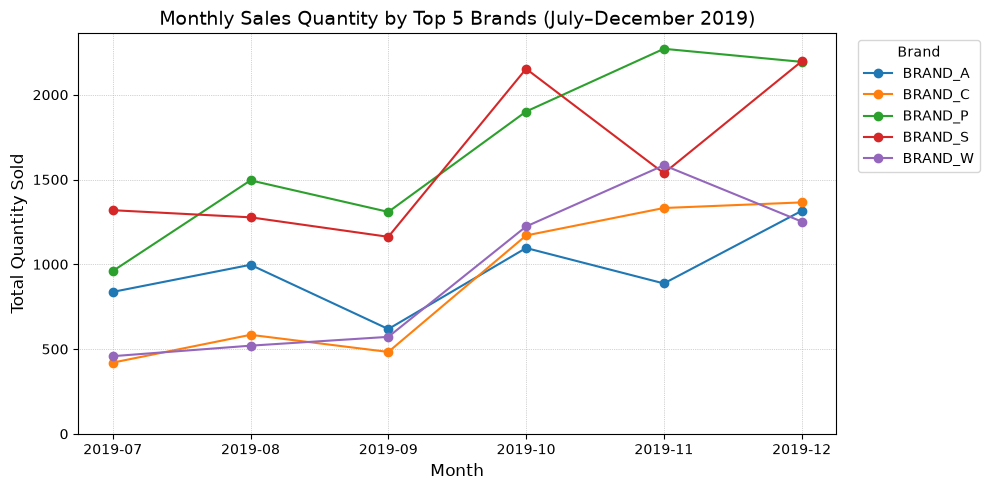

In [210]:
# Visualize monthly quantity sold by the top 5 brands
top5_monthly_sales.pivot(
    index="order_month",
    columns="brand",
    values="quantity"
).plot(marker="o", figsize=(10, 5))

plt.title("Monthly Sales Quantity by Top 5 Brands (July–December 2019)",
          fontsize=14)
plt.xlabel("Month", fontsize=12)
plt.ylabel("Total Quantity Sold", fontsize=12)
plt.grid(color="darkgray", linestyle=":", linewidth=0.5)
plt.ylim(ymin=0)
plt.legend(title="Brand", loc="upper left",
           bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

**Key Takeaway**

Sales quantity varied across the five leading brands throughout the observed period. BRAND_P recorded the highest sales quantity in most months, peaking at 2,271 units in November. BRAND_S also performed strongly, reaching 2,197 units in December, slightly above BRAND_P at 2,194 units.

Sales quantity increased notably across several brands in October, particularly BRAND_S and BRAND_C. However, the monthly trends differed by brand, indicating that overall sales movements were not uniform across the leading brands.

By December, BRAND_P and BRAND_S remained the strongest performers by sales quantity, while BRAND_A, BRAND_C, and BRAND_W showed different growth patterns throughout the period.

In [211]:
# Calculate total GMV by brand
brand_gmv = (
    df_clean.groupby("brand")["gmv"]
    .sum()
    .sort_values(ascending=False)
)

print(brand_gmv)

brand
BRAND_S    5698822000
BRAND_R    4663577000
BRAND_P    4130269000
BRAND_W    3432990000
BRAND_J    3240858000
BRAND_C    2869944000
BRAND_A    2681869000
BRAND_L    2241572000
BRAND_B    2094474000
BRAND_H    1901131000
Name: gmv, dtype: int64


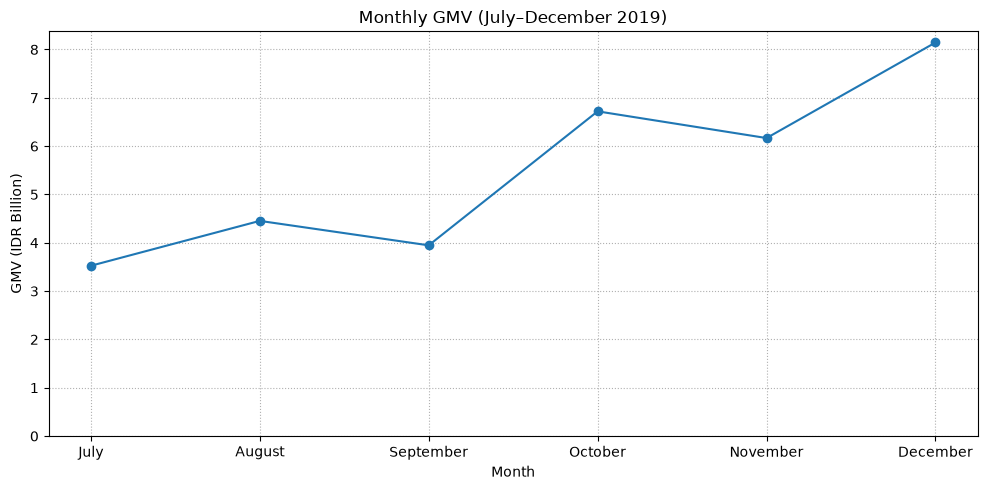

In [212]:
# Visualize monthly GMV
plt.figure(figsize=(10, 5))

month_names = ["July", "August", "September", "October", "November", "December"]

plt.plot(
    month_names,
    monthly_sales["total_gmv"] / 1_000_000_000,
    marker="o"
)

plt.title("Monthly GMV (July–December 2019)")
plt.xlabel("Month")
plt.ylabel("GMV (IDR Billion)")
plt.grid(True, linestyle=":")
plt.ylim(ymin=0)
plt.tight_layout()
plt.show()

**Key Takeaway**

Monthly GMV fluctuated throughout the observed period, following a pattern similar to sales quantity. GMV increased from IDR 3.52 billion in July to IDR 4.45 billion in August, before declining to IDR 3.95 billion in September.

In October, GMV rose significantly to IDR 6.72 billion, followed by a decrease to IDR 6.17 billion in November. December recorded the highest GMV at IDR 8.14 billion.

Overall, GMV showed an upward trend toward the end of 2019, despite month-to-month fluctuations.

In [213]:
# Calculate month-over-month GMV growth (%)
monthly_sales["gmv_growth_pct"] = (
    monthly_sales["total_gmv"].pct_change() * 100
)

print(monthly_sales[["order_month", "total_gmv", "gmv_growth_pct"]])

  order_month   total_gmv  gmv_growth_pct
0     2019-07  3524041000             NaN
1     2019-08  4452923000       26.358433
2     2019-09  3947002000      -11.361548
3     2019-10  6719937000       70.254208
4     2019-11  6166953000       -8.229006
5     2019-12  8144650000       32.069273


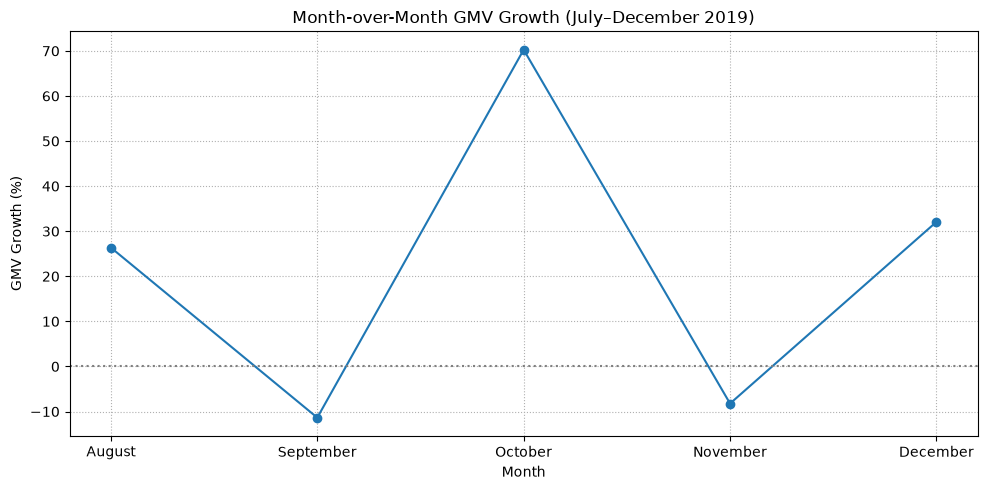

In [214]:
# Visualize monthly GMV growth
month_names = ["July", "August", "September", "October", "November", "December"]

plt.figure(figsize=(10, 5))

plt.plot(
    month_names,
    monthly_sales["gmv_growth_pct"],
    marker="o"
)

plt.title("Month-over-Month GMV Growth (July–December 2019)")
plt.xlabel("Month")
plt.ylabel("GMV Growth (%)")
plt.axhline(y=0, color="gray", linestyle=":")
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

**Key Takeaway**

Month-over-month GMV growth fluctuated throughout the observed period. The largest increase occurred in October, when GMV grew by 70.25% compared with September. This was followed by a 32.07% increase in December and a 26.36% increase in August.

In contrast, GMV declined by 11.36% in September and 8.23% in November compared with the previous months.

These fluctuations indicate that sales value did not grow consistently each month. October's substantial increase stands out as the strongest monthly growth during the observed period, while December ended the year with the highest GMV.

## Brand Performance by GMV

This section compares the five brands with the highest Gross Merchandise Value (GMV) from July to December 2019. Unlike sales quantity, GMV reflects the total transaction value generated by each brand.

Comparing brand performance by GMV and sales quantity helps identify whether the brands selling the most units also generate the highest transaction value.

In [215]:
# Select the top 5 brands by total GMV
top5_gmv = brand_gmv.head(5)

print(top5_gmv)

brand
BRAND_S    5698822000
BRAND_R    4663577000
BRAND_P    4130269000
BRAND_W    3432990000
BRAND_J    3240858000
Name: gmv, dtype: int64


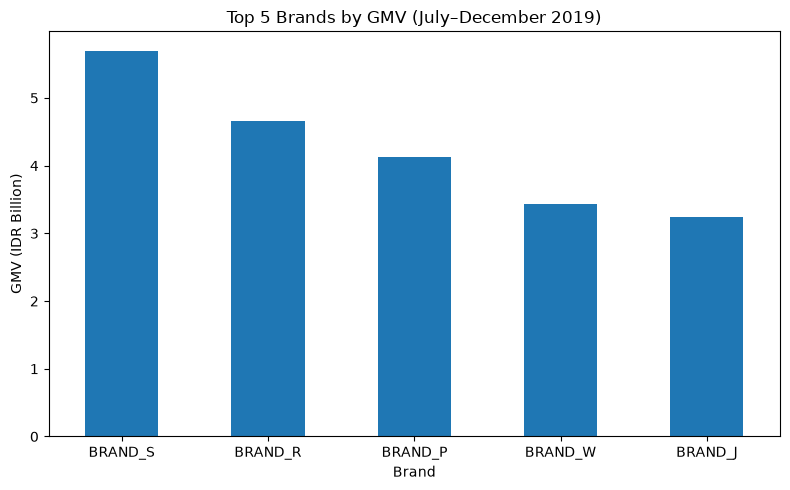

In [216]:
# Visualize top 5 brands by GMV
top5_gmv = brand_gmv.head(5)

(top5_gmv / 1_000_000_000).plot(kind="bar", figsize=(8, 5))

plt.title("Top 5 Brands by GMV (July–December 2019)")
plt.xlabel("Brand")
plt.ylabel("GMV (IDR Billion)")
plt.ylim(ymin=0)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Key Takeaway**

BRAND_S recorded the highest GMV at IDR 5.70 billion, followed by BRAND_R at IDR 4.66 billion and BRAND_P at IDR 4.13 billion. BRAND_W and BRAND_J ranked fourth and fifth, respectively.

The ranking differs from the sales quantity analysis. BRAND_P ranked first in total quantity sold, while BRAND_S generated the highest GMV. BRAND_R also ranked second by GMV despite not appearing among the top five brands by sales quantity.

These differences highlight the importance of evaluating brand performance using both sales volume and transaction value, as the two metrics provide different perspectives on business performance.

## Quarterly Sales Performance: Q3 vs Q4 2019

This section compares sales performance between the third quarter (Q3: July–September) and the fourth quarter (Q4: October–December) of 2019.

Both total sales quantity and GMV are examined to assess changes in sales volume and transaction value between the two quarters.

In [217]:
# Assign each month to its quarter
df_clean["quarter"] = df_clean["order_month"].apply(
    lambda x: "Q3" if x <= "2019-09" else "Q4"
)

print(df_clean[["order_month", "quarter"]].drop_duplicates().sort_values("order_month"))

  order_month quarter
5     2019-07      Q3
3     2019-08      Q3
7     2019-09      Q3
0     2019-10      Q4
2     2019-11      Q4
8     2019-12      Q4


In [218]:

# Calculate quarterly sales performance
quarterly_sales = (
    df_clean.groupby("quarter")
    .agg(
        total_quantity=("quantity", "sum"),
        total_gmv=("gmv", "sum")
    )
    .reindex(["Q3", "Q4"])
)

print(quarterly_sales)

         total_quantity    total_gmv
quarter                             
Q3                21518  11923966000
Q4                35488  21031540000


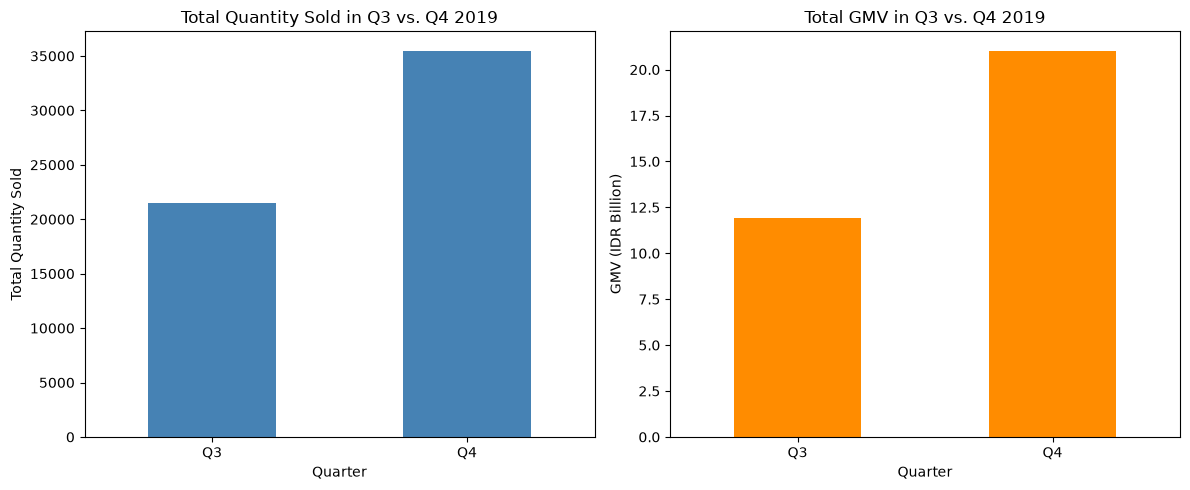

In [219]:
# Visualize quarterly sales performance
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
quarterly_sales["total_quantity"].plot(kind="bar", color="steelblue")
plt.title("Total Quantity Sold in Q3 vs. Q4 2019")
plt.xlabel("Quarter")
plt.ylabel("Total Quantity Sold")
plt.xticks(rotation=0)
plt.ylim(ymin=0)

plt.subplot(1, 2, 2)
(quarterly_sales["total_gmv"] / 1_000_000_000).plot(kind="bar", color="darkorange")
plt.title("Total GMV in Q3 vs. Q4 2019")
plt.xlabel("Quarter")
plt.ylabel("GMV (IDR Billion)")
plt.xticks(rotation=0)
plt.ylim(ymin=0)

plt.tight_layout()
plt.show()

**Key Takeaway**

Sales performance improved substantially in Q4 compared with Q3 2019. Total sales quantity increased from 21,518 units in Q3 to 35,488 units in Q4, while total GMV rose from IDR 11.92 billion to IDR 19.03 billion.

These results indicate that the business generated both higher sales volume and greater transaction value in the fourth quarter. This improvement was consistent with the stronger monthly sales performance observed in October and December.

However, the comparison describes overall quarterly performance and does not, by itself, establish the factors that caused the increase.

In [220]:
print(df_clean[["order_month", "quarter"]].head())

  order_month quarter
0     2019-10      Q4
1     2019-10      Q4
2     2019-11      Q4
3     2019-08      Q3
4     2019-10      Q4


In [221]:
# Calculate the number of unique products sold by the top 5 brands
top5_product_count = (
    df_clean[df_clean["brand"].isin(top5_brands.index)]
    .groupby("brand")["product_id"]
    .nunique()
    .sort_values(ascending=False)
)

print(top5_product_count)

brand
BRAND_S    269
BRAND_P    195
BRAND_C    166
BRAND_A    124
BRAND_W    109
Name: product_id, dtype: int64


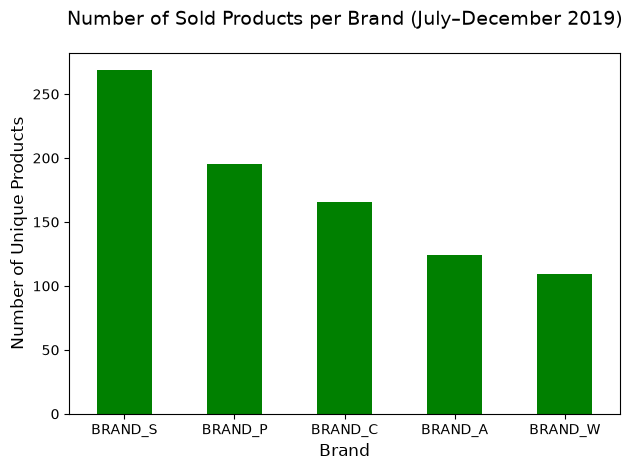

In [222]:
# Visualize the number of unique products sold by the top 5 brands
plt.clf()

top5_product_count.plot(kind="bar", color="green")

plt.title("Number of Sold Products per Brand (July–December 2019)",
          loc="center", pad=20, fontsize=14)
plt.xlabel("Brand", fontsize=12)
plt.ylabel("Number of Unique Products", fontsize=12)
plt.ylim(ymin=0)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Key Takeaway**

BRAND_S had the largest number of sold products, with 269 unique products, followed by BRAND_P with 195 products and BRAND_C with 166 products. BRAND_A and BRAND_W recorded 124 and 109 products, respectively.

Interestingly, BRAND_S had the highest number of sold products, while BRAND_P ranked first in total sales quantity. This suggests that the brand with the widest range of products sold was not necessarily the brand with the highest sales volume.

Further analysis of product-level sales could help identify whether sales were distributed across many products or concentrated in a smaller number of high-volume products.

In [223]:
# Calculate total quantity sold for each product by brand
top5_product_sales = (
    df_clean[df_clean["brand"].isin(top5_brands.index)]
    .groupby(["brand", "product_id"])["quantity"]
    .sum()
    .reset_index()
)

print(top5_product_sales.head())

     brand product_id  quantity
0  BRAND_A      P0002         5
1  BRAND_A      P0003       437
2  BRAND_A      P0029        26
3  BRAND_A      P0030        31
4  BRAND_A      P0032         1


In [224]:
# Classify products by total quantity sold
top5_product_sales["quantity_group"] = top5_product_sales["quantity"].apply(
    lambda x: ">= 100" if x >= 100 else "< 100"
)


print(top5_product_sales.head())

     brand product_id  quantity quantity_group
0  BRAND_A      P0002         5          < 100
1  BRAND_A      P0003       437         >= 100
2  BRAND_A      P0029        26          < 100
3  BRAND_A      P0030        31          < 100
4  BRAND_A      P0032         1          < 100


In [225]:
# Count products in each quantity group by brand
product_group_counts = (
    top5_product_sales.groupby(["brand", "quantity_group"])["product_id"]
    .nunique()
    .unstack(fill_value=0)
)

# Sort brands by total number of products
product_group_counts = product_group_counts.reindex(top5_product_count.index)

print(product_group_counts)

quantity_group  < 100  >= 100
brand                        
BRAND_S           246      23
BRAND_P           169      26
BRAND_C           156      10
BRAND_A           114      10
BRAND_W            97      12


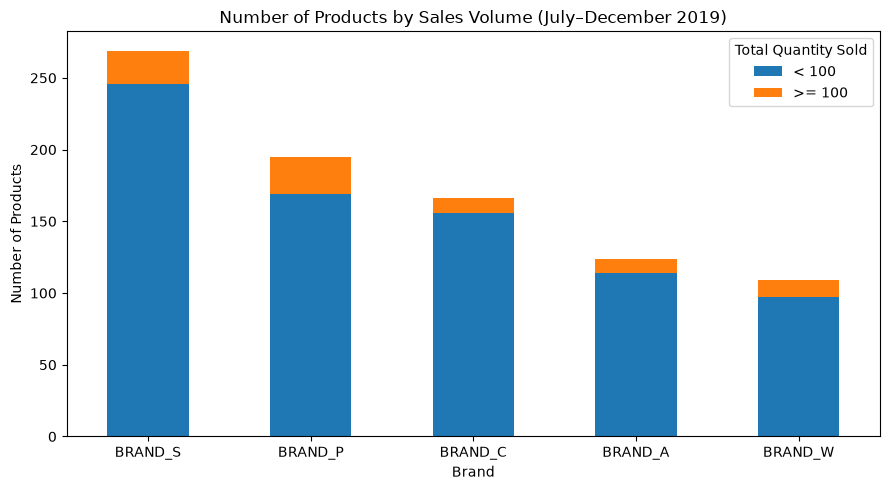

In [226]:
# Visualize product sales groups by brand
product_group_counts.plot(kind="bar", stacked=True, figsize=(9, 5))

plt.title("Number of Products by Sales Volume (July–December 2019)")
plt.xlabel("Brand")
plt.ylabel("Number of Products")
plt.ylim(ymin=0)
plt.xticks(rotation=0)
plt.legend(title="Total Quantity Sold")
plt.tight_layout()
plt.show()

**Key Takeaway**

Most products across the five leading brands recorded total sales below 100 units during the observed period. BRAND_S had 246 products in this category, followed by BRAND_P with 169 and BRAND_C with 156.

In contrast, BRAND_P had the highest number of products with sales of at least 100 units, at 26 products, followed by BRAND_S with 23 products. This suggests that although BRAND_S had the largest number of unique products sold, BRAND_P had more products reaching the 100-unit threshold.

These findings highlight differences in product-level sales patterns across brands. Further analysis could examine whether sales were concentrated in a small number of high-volume products or distributed more evenly across each brand's products.

In [227]:
# Calculate median price for each product
median_price = df_clean.groupby("product_id")["item_price"].median()

print(median_price.head())

# Check the highest median product prices
print(median_price.sort_values(ascending=False).head(10))

product_id
P0002     904000.0
P0003     450000.0
P0009     450000.0
P0011    5945000.0
P0029     310000.0
Name: item_price, dtype: float64
product_id
P2083    29762000.0
P3390    13995000.0
P0074    11545000.0
P4058    10495000.0
P0625    10495000.0
P3200     8745000.0
P3044     6995000.0
P0143     6645000.0
P2803     6312000.0
P3433     5945000.0
Name: item_price, dtype: float64


In [228]:
print(median_price.describe())

count    1.322000e+03
mean     1.004075e+06
std      1.429806e+06
min      2.600000e+04
25%      3.100000e+05
50%      5.900000e+05
75%      1.104000e+06
max      2.976200e+07
Name: item_price, dtype: float64


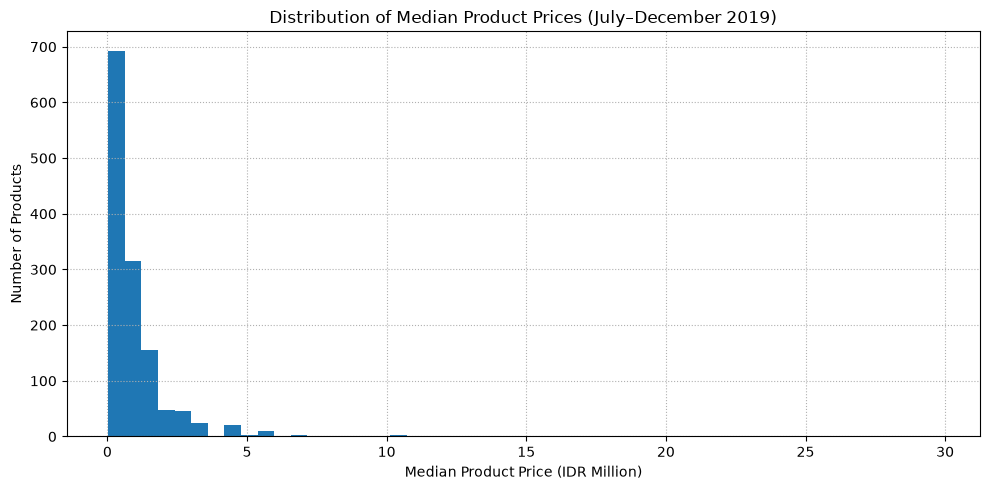

In [229]:
# Visualize the distribution of median product prices
plt.figure(figsize=(10, 5))

(median_price / 1_000_000).plot(kind="hist", bins=50)

plt.title("Distribution of Median Product Prices (July–December 2019)")
plt.xlabel("Median Product Price (IDR Million)")
plt.ylabel("Number of Products")
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

**Key Takeaway**

The histogram shows a right-skewed distribution of median product prices, indicating that most products had relatively low median prices, while a smaller number of products had substantially higher prices.

This pattern is supported by the median price of IDR 590,000, which was lower than the mean of approximately IDR 1.00 million. The difference suggests that high-priced products pulled the average upward.

Overall, product prices were concentrated in the lower price ranges, with a small number of high-priced products contributing to the long right tail of the distribution.

In [230]:
# Calculate total quantity and GMV for each product
product_performance = (
    df_clean.groupby("product_id")
    .agg(
        total_quantity=("quantity", "sum"),
        total_gmv=("gmv", "sum")
    )
    .reset_index()
)

print(product_performance.head())

  product_id  total_quantity  total_gmv
0      P0002               5    4520000
1      P0003             437  167050000
2      P0009              12    5400000
3      P0011               4   23780000
4      P0029              26    8606000


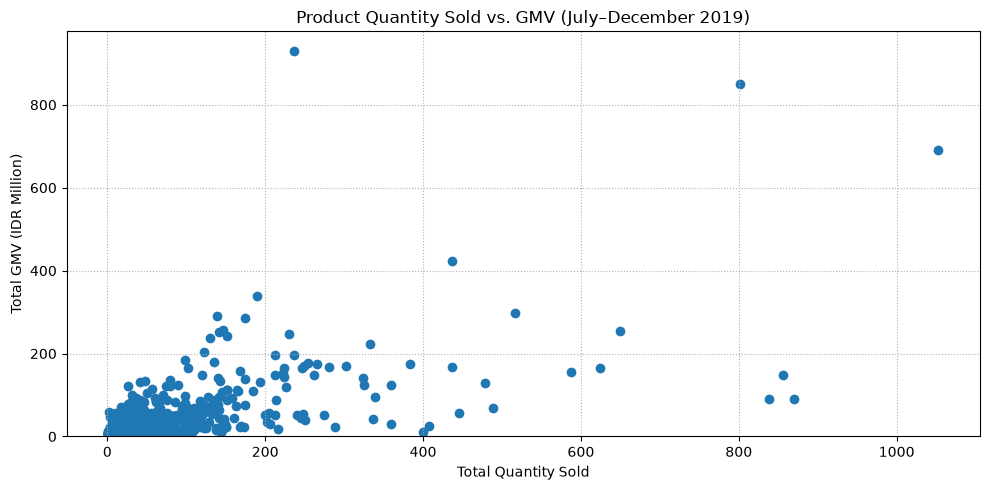

In [231]:
# Visualize the relationship between quantity sold and GMV
plt.figure(figsize=(10, 5))

plt.scatter(
    product_performance["total_quantity"],
    product_performance["total_gmv"] / 1_000_000
)

plt.title("Product Quantity Sold vs. GMV (July–December 2019)")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Total GMV (IDR Million)")
plt.grid(True, linestyle=":")
plt.ylim(bottom=0)
plt.tight_layout()
plt.show()

**Key Takeaway**

The scatter plot shows a general positive relationship between total quantity sold and GMV across products from July to December 2019. Products with higher sales quantities generally tended to generate higher GMV, although the relationship was not consistent across all products.

Most products were concentrated in the lower ranges of both sales quantity and GMV. Meanwhile, a small number of products recorded substantially higher sales quantities or GMV than the majority of products.

These findings suggest that product-level sales performance varied considerably. Evaluating both quantity sold and GMV provides a more complete view of product performance, as products with similar sales quantities may generate different transaction values.

In [232]:
# Combine median product prices and total quantity sold
price_quantity = pd.concat(
    [
        median_price.rename("median_price"),
        product_performance.set_index("product_id")["total_quantity"]
    ],
    axis=1
)

print(price_quantity.head())

            median_price  total_quantity
product_id                              
P0002           904000.0               5
P0003           450000.0             437
P0009           450000.0              12
P0011          5945000.0               4
P0029           310000.0              26


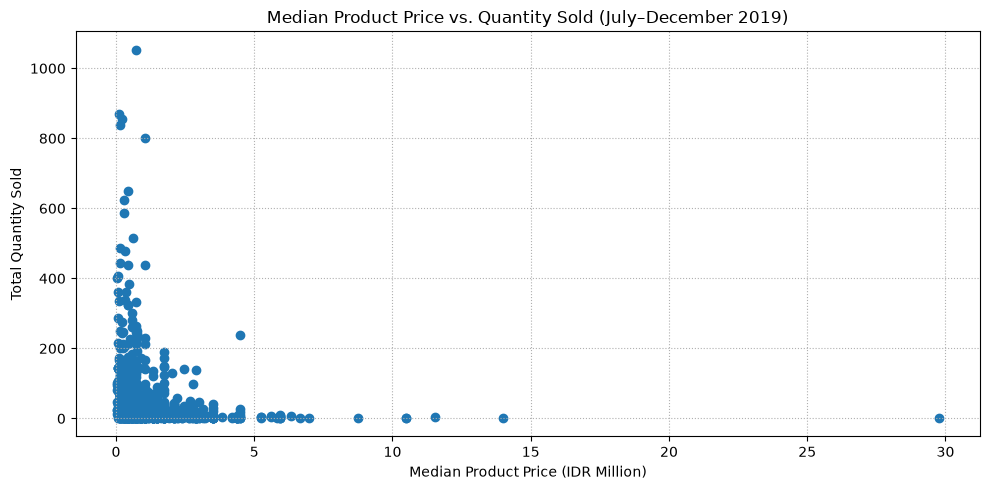

In [233]:
# Visualize the relationship between median price and quantity sold
plt.figure(figsize=(10, 5))

plt.scatter(
    price_quantity["median_price"] / 1_000_000,
    price_quantity["total_quantity"]
)

plt.title("Median Product Price vs. Quantity Sold (July–December 2019)")
plt.xlabel("Median Product Price (IDR Million)")
plt.ylabel("Total Quantity Sold")
plt.grid(True, linestyle=":")
plt.tight_layout()
plt.show()

**Key Takeaway**

The chart shows that products with lower median prices generally sold more units than higher-priced products. Most high-priced products had relatively low sales quantities.

Some lower-priced products sold more than 800 units, while several products priced above IDR 5 million sold very few units.

Overall, lower-priced products tended to achieve higher sales volumes, although this pattern was not consistent across all products. Further analysis would be needed to determine whether price differences are associated with changes in product demand.

In [234]:
# Calculate total GMV by province
province_gmv = (
    df_clean.groupby("province")["gmv"]
    .sum()
    .sort_values(ascending=False)
)

print(province_gmv)

province
DKI Jakarta    14886447000
Jawa Barat      6128149000
Jawa Tengah     3485884000
Yogyakarta      3110196000
Jawa Timur      2647986000
Banten          1495632000
Bali            1201212000
Name: gmv, dtype: int64


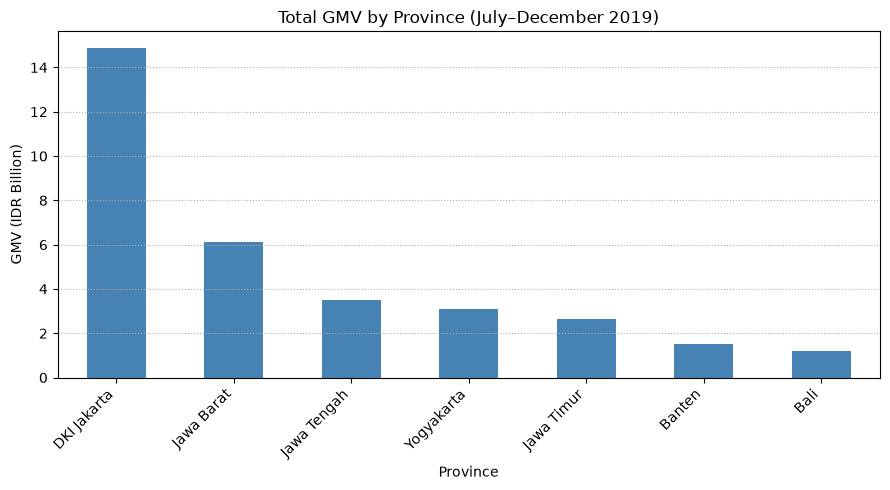

In [235]:
# Visualize total GMV by province
(province_gmv / 1_000_000_000).plot(
    kind="bar",
    figsize=(9, 5),
    color="steelblue"
)

plt.title("Total GMV by Province (July–December 2019)")
plt.xlabel("Province")
plt.ylabel("GMV (IDR Billion)")
plt.xticks(rotation=45, ha="right")
plt.ylim(ymin=0)
plt.grid(axis="y", linestyle=":")
plt.tight_layout()
plt.show()

**Key Takeaway**

DKI Jakarta recorded the highest GMV at IDR 14.89 billion, followed by West Java at IDR 6.13 billion. Central Java ranked third with IDR 3.49 billion.

GMV in DKI Jakarta was more than twice that of West Java, showing a large gap in transaction value between the two provinces. Meanwhile, Bali recorded the lowest GMV among the seven provinces, at IDR 1.20 billion.

Overall, sales value was concentrated in DKI Jakarta compared with the other provinces. Further analysis could help identify the factors behind these regional differences.

In [236]:
# Calculate total GMV by city
city_gmv = (
    df_clean.groupby("city")["gmv"]
    .sum()
    .sort_values(ascending=False)
)

print(city_gmv.head(10))

city
Jakarta Selatan    5247438000
Jakarta Pusat      4006875000
Yogyakarta         3110196000
Bogor              2803750000
Jakarta Barat      2035115000
Jakarta Utara      1974986000
Malang             1966069000
Surakarta          1943111000
Jakarta Timur      1622033000
Tangerang          1495632000
Name: gmv, dtype: int64


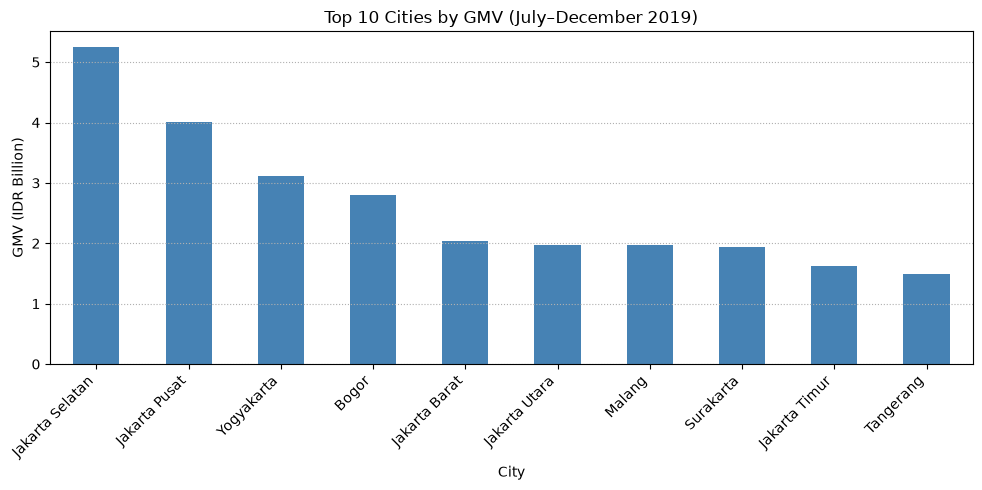

In [237]:
# Visualize the top 10 cities by GMV
top10_city_gmv = city_gmv.head(10) / 1_000_000_000

top10_city_gmv.plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Top 10 Cities by GMV (July–December 2019)")
plt.xlabel("City")
plt.ylabel("GMV (IDR Billion)")
plt.xticks(rotation=45, ha="right")
plt.ylim(ymin=0)
plt.grid(axis="y", linestyle=":")
plt.tight_layout()
plt.show()

**Key Takeaway**

South Jakarta recorded the highest GMV among the top 10 cities, at IDR 5.25 billion, followed by Central Jakarta at IDR 4.01 billion. Yogyakarta ranked third with IDR 3.11 billion.

The five cities in Jakarta contributed a large share of the GMV among the top 10 cities. South Jakarta also generated a higher GMV than any other city in the list.

Meanwhile, Tangerang recorded the lowest GMV among the top 10 cities, at IDR 1.50 billion. These results show that GMV varied across cities, with South Jakarta leading the ranking during July–December 2019.

## 3. Customer Purchasing Behavior

This section examines customer purchasing patterns to understand how frequently customers placed orders during the observed period.

By analyzing the number of orders per customer, we can assess whether purchasing activity was mainly driven by one-time buyers or customers who placed multiple orders.

In [238]:
# Calculate the number of orders per customer
customer_orders = (
    df_clean.groupby("customer_id")["order_id"]
    .nunique()
    .sort_values(ascending=False)
)

print(customer_orders.describe())
print("\nTop 10 customers by number of orders:")
print(customer_orders.head(10))

count    1773.000000
mean        1.824027
std         2.098196
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        50.000000
Name: order_id, dtype: float64

Top 10 customers by number of orders:
customer_id
17841    50
12748    41
14606    23
13089    15
14096    14
15311    11
13263    10
17511    10
14194    10
16764     9
Name: order_id, dtype: int64


In [239]:
# Count customers by number of orders
order_frequency = customer_orders.value_counts().sort_index()

print(order_frequency)

order_id
1     1100
2      344
3      185
4       61
5       28
6       22
7       10
8        5
9        9
10       3
11       1
14       1
15       1
23       1
41       1
50       1
Name: count, dtype: int64


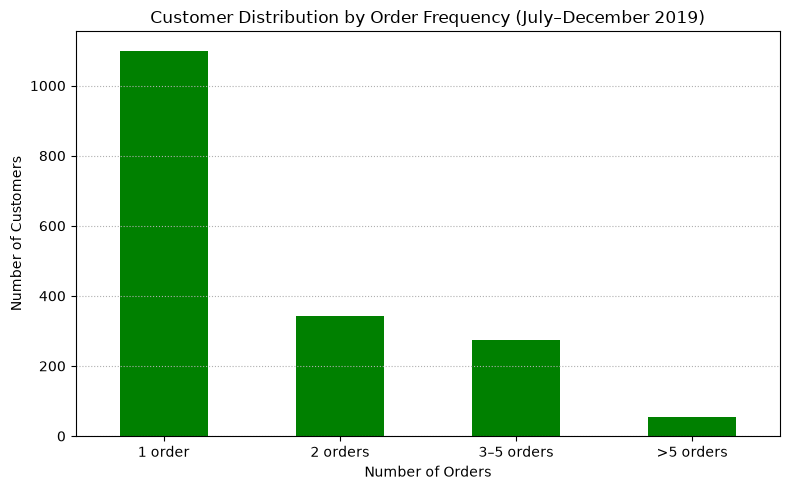

In [240]:
# Group customers by order frequency
customer_order_groups = pd.Series({
    "1 order": (customer_orders == 1).sum(),
    "2 orders": (customer_orders == 2).sum(),
    "3–5 orders": customer_orders.between(3, 5).sum(),
    ">5 orders": (customer_orders > 5).sum()
})

# Visualize customer distribution by order frequency
customer_order_groups.plot(
    kind="bar",
    figsize=(8, 5),
    color="green"
)

plt.title("Customer Distribution by Order Frequency (July–December 2019)")
plt.xlabel("Number of Orders")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.ylim(ymin=0)
plt.grid(axis="y", linestyle=":")
plt.tight_layout()
plt.show()

**Key Takeaway**

Most customers placed only one order during the observed period. Out of 1,773 unique customers, 1,100 customers placed one order, while 673 customers placed more than one order.

This suggests that purchasing activity was largely driven by one-time buyers. Encouraging these customers to make repeat purchases could be an opportunity to improve customer retention.

However, the analysis covers only July to December 2019, so customers classified as one-time buyers may have purchased outside the observed period.

## Top 10 Customers by GMV

This section identifies the ten customers with the highest cumulative GMV from July to December 2019.

By comparing their combined GMV with total GMV, we can assess how much transaction value was contributed by the highest-value customers.

In [241]:
# Calculate total GMV by customer
customer_gmv = (
    df_clean.groupby("customer_id")["gmv"]
    .sum()
    .sort_values(ascending=False)
)

print(customer_gmv.head(10))

customer_id
17450    1152928000
16684     784768000
18102     601742000
17511     489846000
16029     481116000
14096     411184000
13694     348360000
17389     329616000
14298     266427000
13798     266348000
Name: gmv, dtype: int64


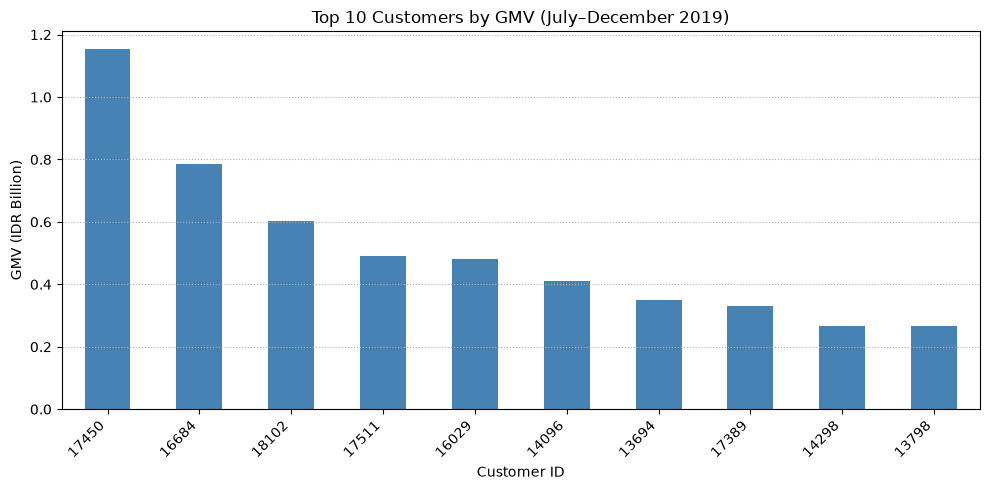

In [242]:
# Visualize the top 10 customers by GMV
top10_customer_gmv = customer_gmv.head(10) / 1_000_000_000

top10_customer_gmv.plot(
    kind="bar",
    figsize=(10, 5),
    color="steelblue"
)

plt.title("Top 10 Customers by GMV (July–December 2019)")
plt.xlabel("Customer ID")
plt.ylabel("GMV (IDR Billion)")
plt.xticks(rotation=45, ha="right")
plt.ylim(ymin=0)
plt.grid(axis="y", linestyle=":")
plt.tight_layout()
plt.show()

In [243]:
# Calculate GMV contribution of the five Jakarta cities
jakarta_cities = [
    "Jakarta Selatan",
    "Jakarta Pusat",
    "Jakarta Barat",
    "Jakarta Utara",
    "Jakarta Timur"
]

jakarta_gmv = city_gmv.loc[jakarta_cities].sum()
top10_gmv = city_gmv.head(10).sum()

print("GMV from five Jakarta cities:", jakarta_gmv)
print("Total GMV of top 10 cities:", top10_gmv)
print("Contribution:", round(jakarta_gmv / top10_gmv * 100, 2), "%")

GMV from five Jakarta cities: 14886447000
Total GMV of top 10 cities: 26205205000
Contribution: 56.81 %


**Key Takeaway**

South Jakarta recorded the highest GMV among the top 10 cities, at IDR 5.25 billion, followed by Central Jakarta at IDR 4.01 billion. Yogyakarta ranked third at IDR 3.11 billion.

The five Jakarta cities in the ranking generated a combined GMV of IDR 14.89 billion, accounting for 56.81% of the total GMV of the top 10 cities. This indicates that more than half of the transaction value within this group came from Jakarta.

Meanwhile, Tangerang recorded the lowest GMV among the top 10 cities, at IDR 1.50 billion. Overall, GMV varied across cities, with South Jakarta leading the ranking during July–December 2019.

In [244]:
# Calculate the GMV contribution of the top 10 customers
total_gmv = df_clean["gmv"].sum()
top10_gmv = customer_gmv.head(10).sum()

top10_contribution = (top10_gmv / total_gmv) * 100

print(f"Total GMV: IDR {total_gmv:,.0f}")
print(f"Top 10 Customers GMV: IDR {top10_gmv:,.0f}")
print(f"Top 10 Customers Contribution: {top10_contribution:.2f}%")

Total GMV: IDR 32,955,506,000
Top 10 Customers GMV: IDR 5,132,335,000
Top 10 Customers Contribution: 15.57%


## Customer Retention Analysis

This section examines how many customers who purchased in Q3 returned to make a purchase in Q4 2019.

Customer retention helps assess whether the business maintained purchasing relationships with existing customers across the two quarters.

In [245]:
# Calculate customer retention rate from Q3 to Q4
q3_customers = set(
    df_clean.loc[df_clean["quarter"] == "Q3", "customer_id"].unique()
)

q4_customers = set(
    df_clean.loc[df_clean["quarter"] == "Q4", "customer_id"].unique()
)

retained_customers = q3_customers.intersection(q4_customers)

retention_rate = len(retained_customers) / len(q3_customers) * 100

print(f"Q3 Customers: {len(q3_customers)}")
print(f"Customers Retained in Q4: {len(retained_customers)}")
print(f"Customer Retention Rate (Q3 to Q4): {retention_rate:.2f}%")

Q3 Customers: 827
Customers Retained in Q4: 434
Customer Retention Rate (Q3 to Q4): 52.48%


In [246]:
# Identify Q4 Customers Without Q3 Purchase
new_customers_q4 = q4_customers - q3_customers

print(f"Total Q4 Customers: {len(q4_customers)}")
print(f"Q4 Customers Without Q3 Purchase: {len(new_customers_q4)}")
print(
    f"NQ4 Customers Without Q3 Purchase Rate: "
    f"{len(new_customers_q4) / len(q4_customers) * 100:.2f}%"
)

Total Q4 Customers: 1380
Q4 Customers Without Q3 Purchase: 946
NQ4 Customers Without Q3 Purchase Rate: 68.55%


In [247]:
# Summarize customer retention and acquisition
customer_summary = pd.DataFrame({
    "Metric": [
        "Q3 Customers",
        "Q4 Customers",
        "Retained Customers",
        "Q4 Customers Without Q3 Purchase",
        "Customer Retention Rate (%)",
        "Q4 Customers Without Q3 Purchase Rate (%)"
    ],
    "Value": [
        len(q3_customers),
        len(q4_customers),
        len(retained_customers),
        len(new_customers_q4),
        round(len(retained_customers) / len(q3_customers) * 100, 2),
        round(len(new_customers_q4) / len(q4_customers) * 100, 2)
    ]
})

print(customer_summary.to_string(index=False, justify="left"))

Metric                                     Value 
                             Q3 Customers  827.00
                             Q4 Customers 1380.00
                       Retained Customers  434.00
         Q4 Customers Without Q3 Purchase  946.00
              Customer Retention Rate (%)   52.48
Q4 Customers Without Q3 Purchase Rate (%)   68.55


In [248]:
display(customer_summary)

,Metric,Value
0,Q3 Customers,827.00
1,Q4 Customers,1380.00
2,Retained Customers,434.00
3,Q4 Customers Without Q3 Purchase,946.00
4,Customer Retention Rate (%),52.48
5,Q4 Customers Without Q3 Purchase Rate (%),68.55


**Key Takeaway**

Of the 827 customers who purchased in Q3 2019, 434 also made a purchase in Q4. This represents a customer retention rate of 52.48%.

Meanwhile, Q4 included 946 customers who had not purchased in Q3, accounting for 68.55% of all Q4 customers. These customers may include first-time buyers during the observed period as well as existing customers whose previous purchases occurred before July 2019. However, the available data does not allow us to distinguish between these groups.

The findings show that 52.48% of Q3 customers continued purchasing in Q4, while a substantial share of Q4 customers had no recorded purchase in Q3. Further analysis would be needed to understand the reasons behind these patterns.

## 4. Conclusion & Business Recommendations

### Conclusion

The analysis of retail transactions from July to December 2019 revealed several patterns in sales performance and customer purchasing behavior.

- **Sales performance:** December recorded the highest monthly sales quantity at 13,507 units and the highest GMV at IDR 8.14 billion. Overall, sales performance improved toward the end of the year, despite monthly fluctuations.
- **Brand performance:** BRAND_P led in total sales quantity, while BRAND_S generated the highest GMV. This shows that brand rankings differ depending on whether performance is measured by sales volume or transaction value.
- **Quarterly performance:** Both sales quantity and GMV increased in Q4 compared with Q3, indicating stronger overall sales performance in the final quarter.
- **Customer behavior:** Most customers placed only one order during the observed period. The retention rate from Q3 to Q4 was 52.48%. Meanwhile, customers without a recorded Q3 purchase accounted for 68.55% of Q4 customers. These customers may have purchased before the observed period, but the available data does not allow us to confirm their previous purchase history.
- **Customer contribution:** The top 10 customers contributed 15.57% of total GMV, highlighting the contribution of high-value customers without indicating that the business depended entirely on them.

### Business Recommendations

1. **Investigate monthly sales drivers.** Examine the factors behind the strong performance in October and December, including promotions, product availability, and seasonal demand, if supporting data is available.
2. **Evaluate brand performance using multiple metrics.** Compare sales quantity and GMV to identify brands that generate high transaction value and brands with strong unit demand.
3. **Encourage repeat purchases.** Consider targeted follow-up campaigns or promotions for customers who have made only one purchase, then evaluate their subsequent purchase behavior.
4. **Monitor customer retention.** Track retention across additional quarters to determine whether the Q3-to-Q4 pattern continues over time.
5. **Maintain relationships with high-value customers.** Monitor purchasing frequency and transaction value among high-GMV customers while continuing to develop the broader customer base.

### Limitations

This analysis covers transactions from July to December 2019 only. Therefore, customers with no recorded purchase in a particular quarter may have purchased outside the observed period. The dataset also does not establish the causes of sales fluctuations or provide enough information to assess profitability, as GMV represents transaction value rather than profit.